# Week 2 Deliverable — Transfer Learning & Augmentation

This Colab notebook compares:
1. A ResNet18 trained from scratch.
2. ImageNet-pretrained ResNet18 without augmentation.
3. ImageNet-pretrained ResNet18 with augmentation.

It generates an ablation table, confusion matrix, per-class metrics, training curves, checkpoints, and a short results write-up.

**Dataset:** CIFAR-10 as a reproducible 10-class image-classification benchmark. If the dataset is already cached in your Colab runtime from Week 1, it should be reused. For best speed, choose **Runtime → Change runtime type → T4 GPU**.

The results are produced when you run the notebook; they are not pre-filled. This is a compact Week 2 experiment, so increase epochs if time allows.


## 1. Setup and configuration

In [ ]:
!pip -q install scikit-learn pandas matplotlib seaborn

import os, time, copy, json, random, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
EPOCHS = 4
BATCH_SIZE = 128
IMAGE_SIZE = 96
DATA_DIR = "/content/data"
OUT = Path("/content/week2_outputs")
OUT.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Enable a GPU in Runtime settings for faster training.")


Device: cuda
GPU: Tesla T4


## 2. Dataset and augmentation setup

In [ ]:
# ImageNet normalization is required for pretrained torchvision weights.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

no_aug = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
with_aug = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(IMAGE_SIZE, padding=8),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_tf = no_aug

# Use the same training indices in all experiments.
train_aug_base = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=with_aug)
train_plain_base = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=no_aug)
val_base = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=test_tf)
test_ds = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=test_tf)

classes = train_aug_base.classes
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(train_aug_base), generator=g).tolist()
train_idx, val_idx = idx[:45000], idx[45000:]

train_aug_ds = Subset(train_aug_base, train_idx)
train_plain_ds = Subset(train_plain_base, train_idx)
val_ds = Subset(val_base, val_idx)

def loader(ds, shuffle=False):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2,
                      pin_memory=torch.cuda.is_available(), persistent_workers=True)

train_aug_loader = loader(train_aug_ds, True)
train_plain_loader = loader(train_plain_ds, True)
val_loader = loader(val_ds)
test_loader = loader(test_ds)

print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_ds)}")
print("Classes:", classes)


100%|██████████| 170M/170M [38:10<00:00, 74.4kB/s]


Train: 45000 | Validation: 5000 | Test: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Model builders

In [ ]:
def build_model(pretrained):
    if pretrained:
        weights = models.ResNet18_Weights.DEFAULT
        model = models.resnet18(weights=weights)
    else:
        model = models.resnet18(weights=None)

    model.fc = nn.Linear(model.fc.in_features, len(classes))

    if pretrained:
        # Phase 1: freeze the backbone and train the new classifier head.
        for p in model.parameters():
            p.requires_grad = False
        for p in model.fc.parameters():
            p.requires_grad = True

    return model.to(DEVICE)

def unfreeze_last_block(model):
    # Fine-tune only the final residual block and new classifier at lower LR.
    for p in model.layer4.parameters():
        p.requires_grad = True
    for p in model.fc.parameters():
        p.requires_grad = True


## 4. Training and evaluation helpers

In [ ]:
def train_epoch(model, dl, criterion, optimizer):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        n = y.size(0)
        loss_sum += loss.item() * n
        correct += (logits.argmax(1) == y).sum().item()
        total += n
    return loss_sum / total, correct / total

@torch.no_grad()
def evaluate(model, dl, criterion):
    model.eval()
    loss_sum, correct, total, ys, ps = 0.0, 0, 0, [], []
    for x, y in dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = model(x)
        loss = criterion(logits, y)
        pred = logits.argmax(1)
        n = y.size(0)
        loss_sum += loss.item() * n
        correct += (pred == y).sum().item()
        total += n
        ys.extend(y.cpu().numpy())
        ps.extend(pred.cpu().numpy())
    return loss_sum / total, correct / total, np.asarray(ys), np.asarray(ps)

def fit(name, model, train_dl, pretrained):
    criterion = nn.CrossEntropyLoss()
    if pretrained:
        optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = -1.0, copy.deepcopy(model.state_dict())
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        # After one head-training epoch, fine-tune layer4 with a smaller LR.
        if pretrained and epoch == 2:
            unfreeze_last_block(model)
            optimizer = torch.optim.Adam([
                {"params": model.layer4.parameters(), "lr": 1e-4},
                {"params": model.fc.parameters(), "lr": 5e-4},
            ], weight_decay=1e-4)

        tr_loss, tr_acc = train_epoch(model, train_dl, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        hist["train_loss"].append(tr_loss); hist["train_acc"].append(tr_acc)
        hist["val_loss"].append(va_loss); hist["val_acc"].append(va_acc)
        print(f"{name} | epoch {epoch}/{EPOCHS} | train acc {tr_acc:.2%} | val acc {va_acc:.2%}")
        if va_acc > best_acc:
            best_acc, best_state = va_acc, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    test_loss, test_acc, y_true, y_pred = evaluate(model, test_loader, criterion)
    torch.save(model.state_dict(), OUT / f"{name}_best.pth")
    with open(OUT / f"{name}_history.json", "w") as f:
        json.dump(hist, f, indent=2)

    return {"experiment": name, "best_val_acc": best_acc, "test_acc": test_acc,
            "test_loss": test_loss, "minutes": (time.time()-start)/60,
            "history": hist, "y_true": y_true, "y_pred": y_pred, "model": model}


## 5. Run the three experiments

In [ ]:
# Scratch baseline (no augmentation)
scratch = fit("scratch_baseline", build_model(False), train_plain_loader, pretrained=False)

# Transfer learning, no augmentation
transfer_plain = fit("pretrained_no_augmentation", build_model(True), train_plain_loader, pretrained=True)

# Transfer learning, with augmentation
transfer_aug = fit("pretrained_with_augmentation", build_model(True), train_aug_loader, pretrained=True)


scratch_baseline | epoch 1/4 | train acc 54.17% | val acc 64.82%
scratch_baseline | epoch 2/4 | train acc 70.06% | val acc 66.98%
scratch_baseline | epoch 3/4 | train acc 76.82% | val acc 73.72%
scratch_baseline | epoch 4/4 | train acc 81.33% | val acc 74.94%
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


pretrained_no_augmentation | epoch 1/4 | train acc 68.13% | val acc 75.46%
pretrained_no_augmentation | epoch 2/4 | train acc 84.34% | val acc 87.48%
pretrained_no_augmentation | epoch 3/4 | train acc 95.50% | val acc 88.94%
pretrained_no_augmentation | epoch 4/4 | train acc 99.14% | val acc 89.04%
pretrained_with_augmentation | epoch 1/4 | train acc 59.20% | val acc 69.36%
pretrained_with_augmentation | epoch 2/4 | train acc 79.40% | val acc 84.20%
pretrained_with_augmentation | epoch 3/4 | train acc 86.12% | val acc 87.34%
pretrained_with_augmentation | epoch 4/4 | train acc 88.35% | val acc 87.90%


## 6. Ablation table

In [ ]:
results = pd.DataFrame([
    {"Experiment": "ResNet18 from scratch, no augmentation",
     "Best validation accuracy (%)": scratch["best_val_acc"]*100,
     "Test accuracy (%)": scratch["test_acc"]*100, "Test loss": scratch["test_loss"],
     "Training time (min)": scratch["minutes"]},
    {"Experiment": "Pretrained ResNet18, no augmentation",
     "Best validation accuracy (%)": transfer_plain["best_val_acc"]*100,
     "Test accuracy (%)": transfer_plain["test_acc"]*100, "Test loss": transfer_plain["test_loss"],
     "Training time (min)": transfer_plain["minutes"]},
    {"Experiment": "Pretrained ResNet18, with augmentation",
     "Best validation accuracy (%)": transfer_aug["best_val_acc"]*100,
     "Test accuracy (%)": transfer_aug["test_acc"]*100, "Test loss": transfer_aug["test_loss"],
     "Training time (min)": transfer_aug["minutes"]},
])
display(results.round(2))
results.to_csv(OUT / "ablation_results.csv", index=False)

transfer_effect = 100 * (transfer_plain["test_acc"] - scratch["test_acc"])
augmentation_effect = 100 * (transfer_aug["test_acc"] - transfer_plain["test_acc"])
print(f"Transfer learning vs scratch: {transfer_effect:+.2f} percentage points")
print(f"Augmentation effect: {augmentation_effect:+.2f} percentage points")


,Experiment,Best validation accuracy (%),Test accuracy (%),Test loss,Training time (min)
0,"ResNet18 from scratch, no augmentation",74.94,74.93,0.75,2.46
1,"Pretrained ResNet18, no augmentation",89.04,88.63,0.40,1.81
2,"Pretrained ResNet18, with augmentation",87.90,87.94,0.35,3.47


Transfer learning vs scratch: +13.70 percentage points
Augmentation effect: -0.69 percentage points


## 7. Confusion matrix and per-class metrics

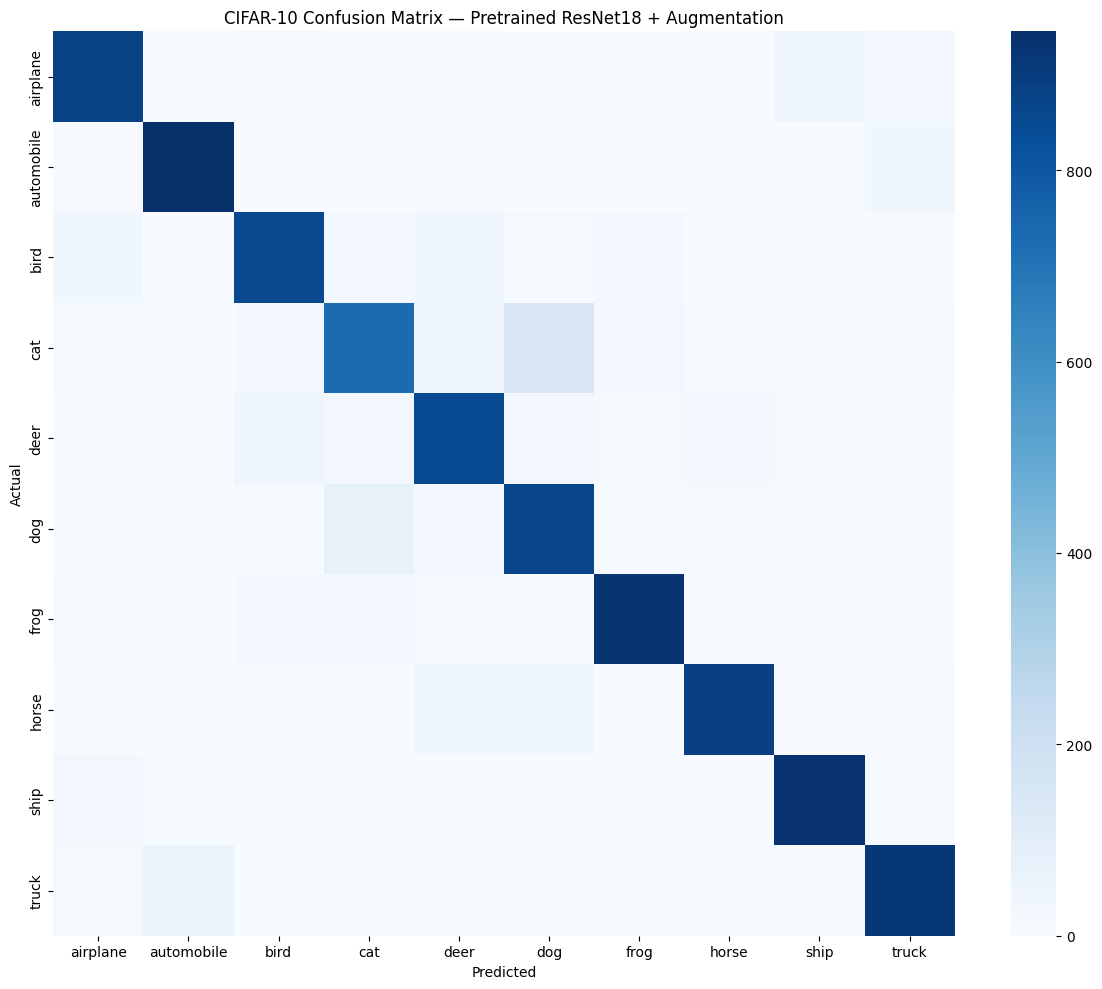

,precision,recall,f1-score,support
airplane,0.898,0.884,0.891,1000.000
automobile,0.920,0.945,0.932,1000.000
bird,0.861,0.854,0.857,1000.000
cat,0.811,0.730,0.768,1000.000
deer,0.851,0.850,0.850,1000.000
dog,0.778,0.868,0.821,1000.000
frog,0.918,0.927,0.922,1000.000
horse,0.915,0.886,0.900,1000.000
ship,0.926,0.933,0.929,1000.000
truck,0.920,0.917,0.918,1000.000


In [ ]:
y_true, y_pred = transfer_aug["y_true"], transfer_aug["y_pred"]
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("CIFAR-10 Confusion Matrix — Pretrained ResNet18 + Augmentation")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=160)
plt.show()

report = classification_report(y_true, y_pred, target_names=classes, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
display(report_df.round(3))
report_df.to_csv(OUT / "per_class_metrics.csv")


## 8. Validation curves and results write-up

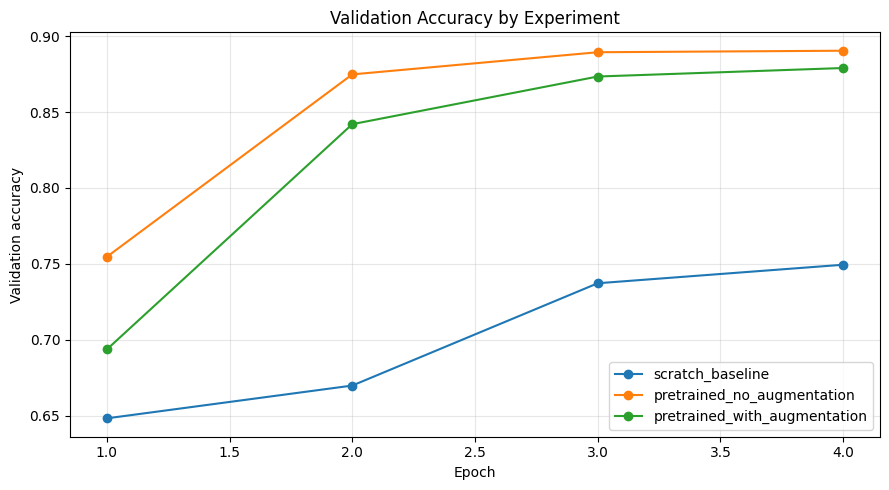

Deliverables ZIP: /content/week2_deliverables.zip
Files: ['pretrained_no_augmentation_history.json', 'pretrained_with_augmentation_best.pth', 'per_class_metrics.csv', 'scratch_baseline_best.pth', 'validation_accuracy_comparison.png', 'ablation_results.csv', 'confusion_matrix.png', 'scratch_baseline_history.json', 'results_writeup.md', 'pretrained_no_augmentation_best.pth', 'pretrained_with_augmentation_history.json', 'metrics.json']


In [ ]:
plt.figure(figsize=(9, 5))
for r in [scratch, transfer_plain, transfer_aug]:
    plt.plot(range(1, EPOCHS+1), r["history"]["val_acc"], marker="o", label=r["experiment"])
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.title("Validation Accuracy by Experiment")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(OUT / "validation_accuracy_comparison.png", dpi=160)
plt.show()

best_row = results.loc[results["Test accuracy (%)"].idxmax()]
aug_text = ("improved" if augmentation_effect > 0 else "reduced" if augmentation_effect < 0 else "did not change")
writeup = f'''# Week 2 Results — Transfer Learning and Data Augmentation

## Setup
- Dataset: CIFAR-10 (10 classes)
- Backbone: ResNet18
- Input resolution: {IMAGE_SIZE}x{IMAGE_SIZE}
- Epochs per experiment: {EPOCHS}
- Optimizer: Adam
- Pretrained runs: ImageNet-pretrained ResNet18; train classifier head first, then fine-tune layer4 and head using lower learning rates.
- Model selection: best validation accuracy; final metrics measured on the official test set.

## Ablation results

{results.round(2).to_markdown(index=False)}

## Interpretation
Transfer learning changed test accuracy by **{transfer_effect:+.2f} percentage points** relative to the from-scratch baseline.

Data augmentation {aug_text} test accuracy by **{augmentation_effect:+.2f} percentage points** compared with pretrained ResNet18 without augmentation. A negative effect is still a valid experimental result; augmentation strength, training duration, and random variation can affect the outcome.

The best measured run was **{best_row["Experiment"]}**, with test accuracy of **{best_row["Test accuracy (%)"]:.2f}%**. These results apply to this run and configuration, not all possible training settings.

## Artifacts
- `ablation_results.csv`: comparison table
- `confusion_matrix.png`: final confusion matrix
- `per_class_metrics.csv`: precision, recall, F1-score, support
- `validation_accuracy_comparison.png`: validation curves
- `*_best.pth`: saved model checkpoints
'''
(OUT / "results_writeup.md").write_text(writeup, encoding="utf-8")
with open(OUT / "metrics.json", "w") as f:
    json.dump({"transfer_effect_pp": transfer_effect, "augmentation_effect_pp": augmentation_effect,
               "results": results.to_dict(orient="records")}, f, indent=2)
zip_path = shutil.make_archive("/content/week2_deliverables", "zip", root_dir=str(OUT))
print("Deliverables ZIP:", zip_path)
print("Files:", [p.name for p in OUT.iterdir()])


## 9. Download the final deliverables

In [ ]:
from google.colab import files
files.download("/content/week2_deliverables.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>